# **Trabalho Prático 2 - Análise Numérica**


Trabalho realizado pelos alunos do Grupo 19 no âmbito da unidade curricular de Análise Numérica (M2018) — 2024/2025:

Bruno	Manuel	Teixeira	Araújo Nº 202207580\
João Pereira Lobato Nº 202306182\
Pedro	Sebastião	Loureiro Pinto	Bessa Nº 202307026

# **Objetivos do Trabalho**

Neste trabalho temos como objetivo responder às questões 1 e 2 disponibilizadas no Moodle, utilizando os nossos conhecimentos sobre o Método de Newton e o Método Iterativo simples, bem como as suas condições suficientes de aplicabilidade e apresentação correta dos valores das raízes a calcular e respetivos erros absolutos majorados ou estimados.

# **Métodos a utilizar**

Para desenvolver os programas a utilizar neste trabalho, recorremos à linguagem Python, uma vez que era aquela com a qual todos os elementos do grupo estavam mais familiarizados, tendo esta sido lecionada em cadeiras anteriores da Licenciatura em Matemática, para além de ser efetivamente simples e de fácil compreensão e leitura.

Todos os cálculos relevantes foram feitos no caderno e depois passados para o trabalho utilizando um convertor de texto Latex.

Utilizamos também o programa GeoGebra para obter os gráficos e pontos mais relevantes para a resolução dos exercícios, que iremos apresentar em imagens devidamente numeradas e identificadas ao longo do trabalho.


# **Questão 1**

**Pretende-se determinar um valor aproximado de um zero de**
**F(x) =** **$sen(x^{2}) + 1.1 − e^{−x}$**



**a) Separem graficamente as raízes de F(x) = 0 e determinem um intervalo I de amplitude**
$10^{−1}$ **que contenha a menor delas.**

**Imagem 1:** Gráfico da função F(x)

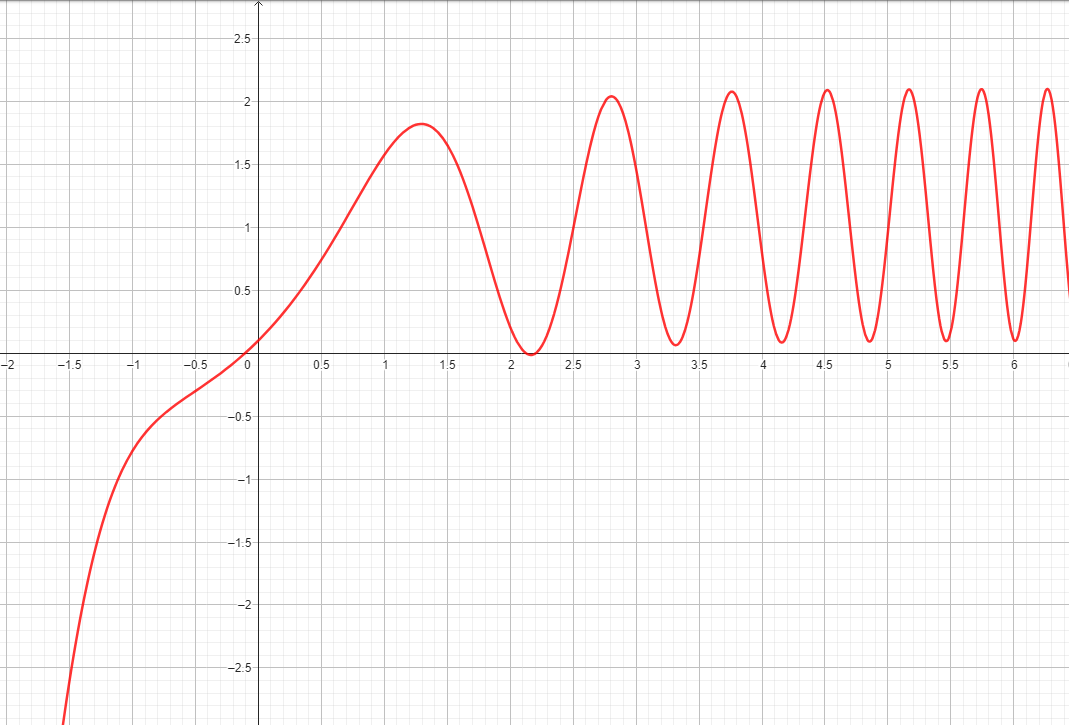

Podemos observar pelo gráfico de F(x) (Imagem 1) que a sua menor raiz será negativa e estará entre -0.5 e 0.
Calculemos de seguida alguns valores da função para encurtar o intervalo para a amplitude pretendida: $10^{-1}$

$
F(0)>0
$

$
F(-0.5)<0\ \ \ \ \ \  logo\ I=[-0.5\ ;0]
$

$
F(-0.2)<0\ \ \ \ \ \ logo\ I=[-0.2\ ;0]
$

$
F(-0.1)>0\ \ \ \ \ \ logo\ I=[-0.2\ ;-0.1] \ <--Amplitude\ pretendida\ (10^{-1})
$

\

Assim, um intervalo I que contém a menor raiz de F(x) com amplitude $10^{-1}$ é por exemplo $I =[-0.2\ ;-0.1]$

**(b) Usando o método iterativo de Newton:**

**i. Mostrem que as condições de aplicabilidade do método são satisfeitas em I**.

**ii. Escrevam um programa que, usando este método, calcule um valor aproximado da
raiz de F(x) = 0 que pertence a I, com erro absoluto (majorado) inferior a um
valor ϵ dado, imprimindo também o número de iterações que foi necessário efetuar.
Usem o vosso programa para calcular um valor aproximado daquela raiz com erro
absoluto estimado inferior a $5 \times 10^{-9}$
.**


i) Temos de mostrar que as seguintes 5 condições são verificadas no Intervalo I=$[-0.2;-0.1]$ (Intervalo I=[a;b]):

1. F, F' e F'' existem e são contínuas em I;
2. F(a)F(b)<0;
3. F'(x)≠0 ∀x ∈ I;
4. F''(x) ≥ 0 ∨ F''(x) ≤ 0 ∀x ∈ I;
5. F(p)F''(p)>0 ,p∈I

Podemos alterar ainda a condição 5 por 5*: $\frac{|F(c)|}{|F'(c)|}$ < b-a, sendo c o extremo de [a,b] onde |F'(x)| atinge o menor valor.

Calcularemos inicialmente a primeira e segunda derivadas de F:

F'(x)= $2xcos(x^{2}) +e^{-x}$

F''(x)= $-4x^{2}sen(x^{2})+2cos(x^{2})-e^{-x}$

Estas existem (pois F e F' são deriváveis) e são ambas contínuas, uma vez que resultam da composição de funções contínuas (polinomiais, trignométricas e exponenciais). (Condição 1 verificada)

Para determinar o intervalo I com a amplitude pretendida na alínea a), já mostramos também que F(-0.2)F(-0.1)<0 (Condição 2 verificada)

Podemos observar a Imagem 2 com o gráfico de F'(x) e de F''(x) para verificar que F'(x) nunca se anula no intervalo I e que F''(x) é sempre positiva em I, verificando-se assim as condições 3 e 4.

Por fim, iremos verificar a condição 5*, uma vez que a condição 5 só se verifica para os valores de I onde F(x)>0 (uma vez que F''(x) é positiva ∀x ∈I).

O extremo de [-0.2;-0.1] onde |F'(x)| é menor é x = -0.2 (pois |F'(x)| é crescente em I) que será o valor de c a usar.

Temos ainda que $b-a=-0.1-(-0.2) = -0.1 + 0.2 = 0.1$ (ver Imagem 2)

Fazendo os cálculos (ver Imagem 2), verificamos que $\frac{|F(-0.2)|}{|F'(-0.2)|}$ < 0.1, estando assim verificada a condição 5*.

Temos assim verificadas as 5 condições suficientes para podermos aplicar o Método de Newton ao intervalo I=[-0.2; -0.1].



**Imagem 2:** Gráfico de F, F' e F'' e cálculos relevantes

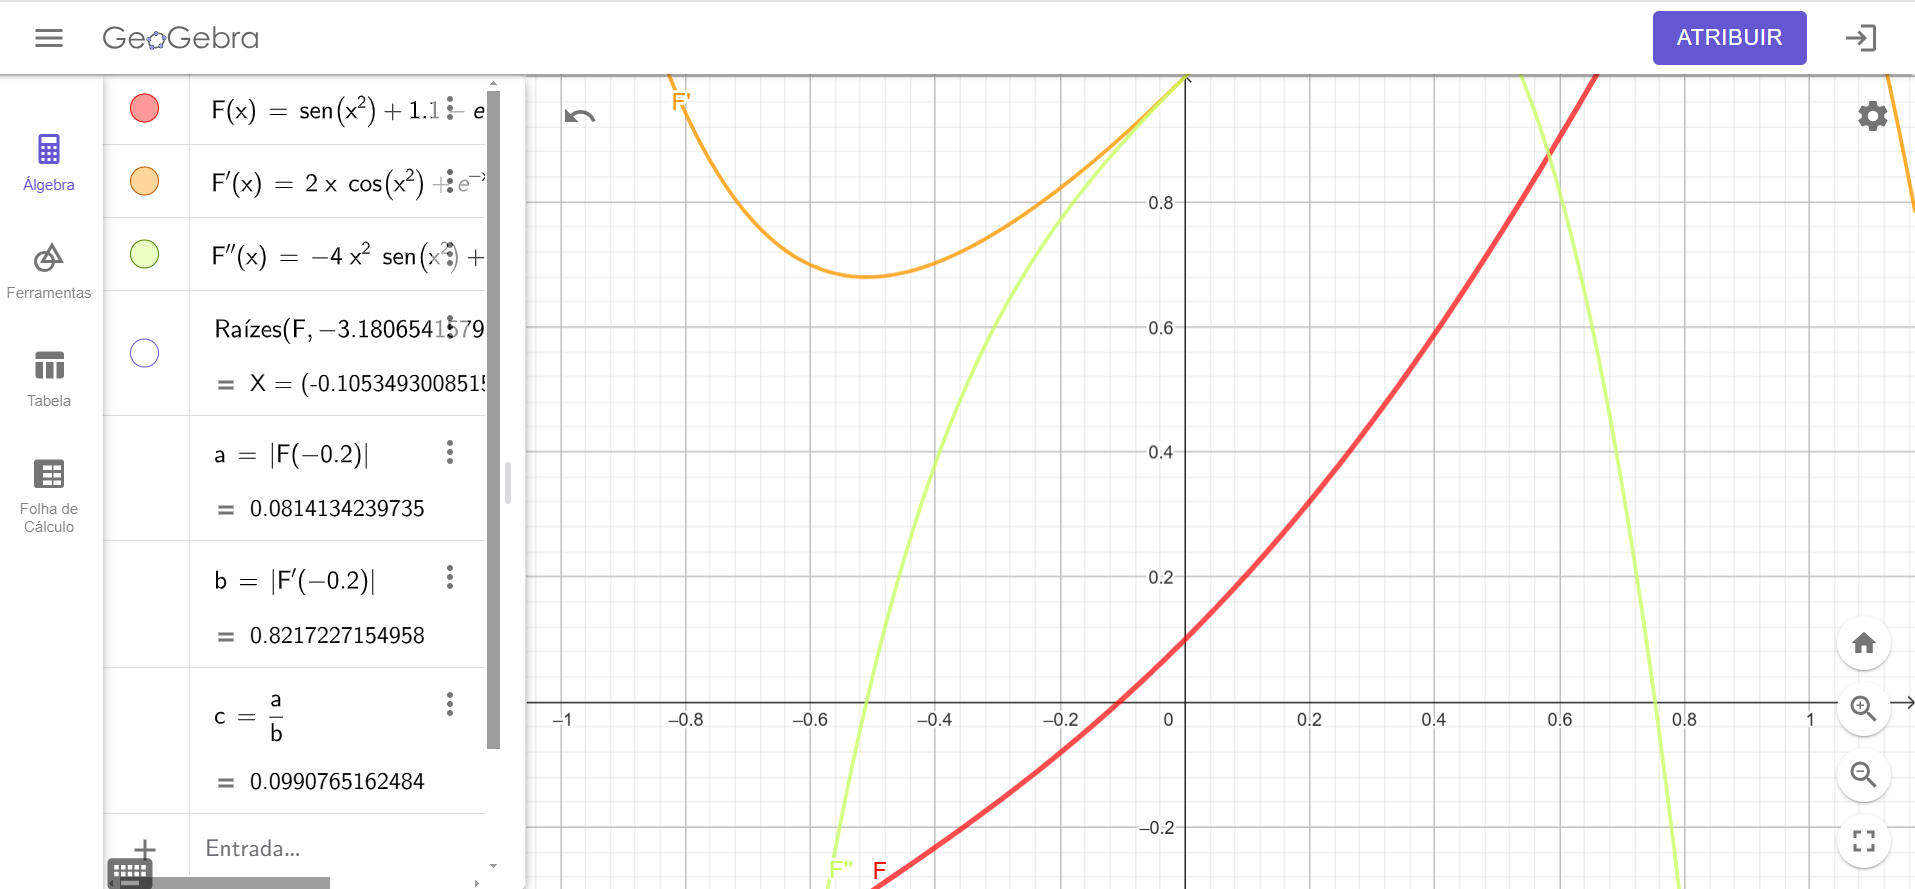

ii)
Resultados obtidos pelo programa criado (ver abaixo):

Valor aproximado da raiz de F(x)=0 com erro
absoluto majorado inferior a $5 \times 10^{-9}  $ :    $-0.1053488533$ ± $5 \times 10^{-9}$

Número de iterações realizadas para determinar o valor aproximado da raiz de F(x)=0 com erro absoluto estimado inferior a $5 \times 10^{-9}$ : $4$

In [ ]:
import math

def df(x):            #função F'(x)
    return 2*x*math.cos(x**2)+math.e**(-x)


def f(x):             #função F(x)
    return math.sin(x**2)-math.e**(-x) + 1.1


def newton(xn,eps):   #Método de Newtwon (recebe xn inicial e eps pretendido)
    cont=0            #contador de número de iterações
    fxn=f(xn)         #valor inicial maior que eps pedido
    while abs(fxn)>eps:
        fxn = f(xn)   #F(xn)
        dfxn = df(xn) #F'(xn)
        xn = xn - (fxn/dfxn)          #Cálculo do novo termo xn
        cont+=1       #incrementar na contagem
    return xn, cont   #retornar valor aproximado da raiz calculada(xn) e número de iterações(cont)
newton(-0.2,5*10**(-9))               #Escrever aqui o valor de xn inicial e valor de eps que pretendemos

(-0.10534885334769928, 4)

# **Questão 2**

**A equação $x^{3} -x^{2}+8x-8 = 0 $ tem apenas uma raiz real X=1. Pretende-se usar o método iterativo simples para determinar um valor aproximado da raiz com erro absoluto estimado inferior a** $10^{−12}$.

**Considerem as seguintes formas iterativas :**

a) $x=g1(x)= -x^{3}+x^{2}-7x+8 $

b) $x=g2(x)= \frac{8-x^{3}}{8-x} $

c) $x=g3(x)= \frac{-1}{10} x^{3} + \frac{1}{10}x^{2} +\frac{1}{5}x +\frac{4}{5} $

d) $x=g4(x)= \frac{2x^{3}-x^{2}+8}{3x^{2}-2x+8} $

\
**i. Apliquem o método iterativo simples em cada caso, a partir do valor inicial x0 = 0.5, sem verificar se as condições suficientes de aplicabilidade do método iterativo simples são satisfeitas.**

**ii. Descrevam e expliquem o que acontece em cada caso.**

**iii. Qual é a melhor forma iterativa (das apresentadas) para encontrar aquela raiz?**
**Justifiquem**

i) Aplicação do Método Iterativo simples para g1,g2,g3 e g4, sem verificar se as condições suficientes de aplicabilidade do método iterativo simples são satisfeitas:

In [ ]:
def g1(x):                   #expressão da função g1
    return -x**3+x**2-7*x+8
def g2(x):                   #expressão da função g2
  return (8-x**3)/(8-x)
def g3(x):                   #expressão da função g3
  return((-1/10)*x**3+(1/10)*x**2+(1/5)*x+4/5)
def g4(x):                   #expressão da função g4
  return (2*x**3 - x**2+8)/(3*x**2-2*x+8)

def mit(g,xi,eps):           #método iterativo simples (recebe a função g a usar, o valor xi inicial e eps pretendido)
    xn=g(xi)
    erroiter=abs(xn-xi)
    cont=1
    while erroiter>eps:      #condição de paragem
        xi=xn
        xn = g(xi)
        erroiter=abs(xn-xi)
        cont+=1              #contador de iterações
    return f"{xn:.17f}",cont #retorna valor aproximado da raiz (xn) e nºde iterações (cont)
#formatamos xn para ser apresentado com 17 casas decimais (valor tem de ser superior a 13) para
#evitar arredondar casas decimais a apresentar nos resultados obtidos em função de eps pedido

#impressão dos resultados pretendidos para g1,g2,g3 e g4 (g1 irá dar erro OverFlow)
#print(mit(g1,0.5,10e-12))   #tirar esta linha para obter resultados de g2,g3 e g4
print(mit(g2,0.5,10e-12))
print(mit(g3,0.5,10e-12))
print(mit(g4,0.5,10e-12))

('1.00000000000069811', 21)
('0.99999999999895550', 12)
('1.00000000000000000', 5)


**Imagem 3 :** OverFlow Error ao tentar imprimir o resultado de g1

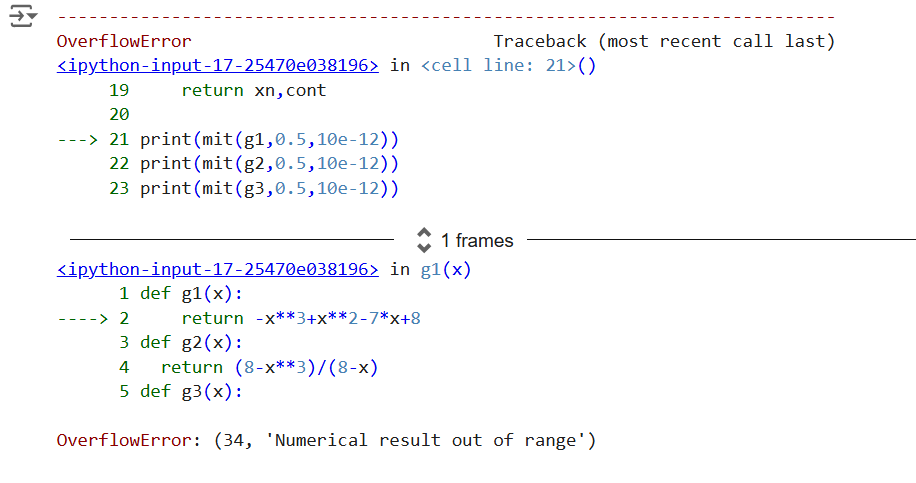

**Imagem 4:** Resultados do programa para g2,g3 e g4

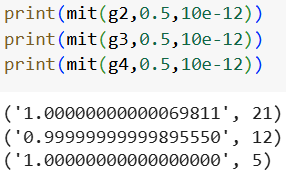

ii) Como podemos ver pela Imagem 3, para g1 não nos é possível calcular um valor aproximado da raiz X, ocorrendo um OverFlow Error, devido à ocorrência de valores demasiado grandes para serem representados pelo Python (os motivos pelos quais isto acontece estão descritos na alínea seguinte). Deste modo, para esta forma iterativa não nos foi possível registar o número de iterações.

Podemos obervar pela Imagem 4, que exibe os resultados do programa desenvolvido em i), que os valores da raiz de F(x)=0 com erro absoluto estimado inferior a $10^{−12} $  para g2, g3 e g4, juntamente com o número de iterações necessárias para o cálculo de cada um são os seguintes:

\

$g2: 1,0000000000007 ± 10^{-12}$ ;$ \ $  $21\ iterações$
\
\
$g3: 0,9999999999990 ± 10^{-12}$ ;$ \ $ $12\ iterações$
\
\
$g4: 1,0000000000000 ± 10^{-12}$ ;$ \ $ $5\ iterações$



iii) Podemos descartar ***g1*** pois a forma iterativa gera uma sequência divergente, ou seja, os valores obtidos através das iterações aumentam rapidamente em magnitude, em vez de convergirem para a raiz pretendida (X = 1). Isto torna ***g1*** inadequada para o método iterativo simples, já que a sequência não se aproxima da solução desejada e leva a valores cada vez maiores, resultando eventualmente num erro de *overflow*.

In [ ]:
def g1(x):                              #Expressão da função g1
    return -x**3 + x**2 - 7 * x + 8

def mit(g, xi, eps):                    # Método iterativo simples
    xn = g(xi)
    erroiter = abs(xn - xi)
    cont = 1
    values = [xi, xn]                   # Lista para armazenar os primeiros valores

    while erroiter > eps and cont < 6:  # Parar após 5 iterações
        xi = xn
        xn = g(xi)
        erroiter = abs(xn - xi)
        values.append(xn)               # Acrescentar novos valores à lista
        cont += 1

    print("Primeiros 5 valores:", values) #Escrita dos primeiros cinco valores registados por g na lista criada


# Chamada para a função mit com g1 e x0 = 0.5
mit(g1, 0.5, 10e-12)


Primeiros 5 valores: [0.5, 4.625, -101.916015625, 1069697.1237782016, -1.224001861234915e+18, 1.833775789385161e+54, -6.166499545700052e+162]


Pelos resultados obtidos no código acima observa-se um crescimento muito rápido na magnitude dos valores, alternando entre positivo e negativo, o que indica que a função não está a aproximar-se de uma solução, mas sim a divergir exponencialmente.

A partir da sétima iteração, a magnitude dos valores torna-se tão grande que ocorre um overflow, ultrapassando os limites de precisão numérica do sistema.

Quanto à aplicação do método iterativo simples às formas iterativas g2, g3 e g4, podemos observar pela Imagem 4 que os resultados do valor aproximado da raiz com erro absoluto estimado inferior a $10^{−12}$ são bastante precisos para as três, tendo no entanto sido necessário um número distinto de iterações em cada uma delas para obter esses mesmos resultados.
Logo, a forma iterativa mais adequada para a utilização do método iterativo simples é aquela que requer um menor número de iterações para chegar ao resultado com o valor de ϵ pretendido, ou seja, aquela que gera uma sucessão que mais rapidamente converge para o valor de X que desejamos.

No código abaixo exibimos um algoritmo que nos retorna os primeiros cinco termos das sucessões geradas pelas formas iterativas g2, g3 e g4, de forma a compararmos a rapidez de convergência das sucessões geradas por estas 3 funções.


In [ ]:
def g2(x):                   #Expressão da função g2
  return (8-x**3)/(8-x)
def g3(x):                   #Expressão da função g3
  return((-1/10)*x**3+(1/10)*x**2+(1/5)*x+4/5)
def g4(x):                   #Expressão da função g4
  return (2*x**3 - x**2+8)/(3*x**2-2*x+8)

def mit(g, xi, eps):         # Método iterativo simples
    xn = g(xi)
    erroiter = abs(xn - xi)
    cont = 1
    values = [xi, xn]        # Lista para armazenar os primeiros valores

    while erroiter > eps and cont < 6:  # Parar após 5 iterações
        xi = xn
        xn = g(xi)
        erroiter = abs(xn - xi)
        values.append(xn)
        cont += 1

    print("Primeiros 5 valores:", values)


# Chamada para a função mit com g2, g3 e g4 e x0 = 0.5
mit(g2, 0.5, 10e-12)
mit(g3, 0.5, 10e-12)
mit(g4, 0.5, 10e-12)


Primeiros 5 valores: [0.5, 1.05, 0.9845143884892086, 1.004312677086027, 0.9987590594698483, 1.0003538320123693, 0.9998988463640411]
Primeiros 5 valores: [0.5, 0.9125000000000001, 0.9897857421875, 0.9989578145726552, 0.9998955643403695, 0.9999895542527895, 0.9999989554034564]
Primeiros 5 valores: [0.5, 1.032258064516129, 1.0002352456847121, 1.000000012299503, 1.0, 1.0]


**Imagem 5:** Primeiros 5 valores obtidos pelas sucessões geradas por g2, g3 e g4:

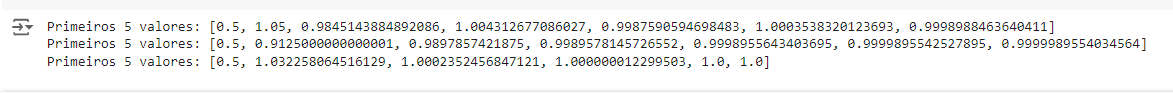

 Portanto, como podemos observar pelos resulados exibidos na Imagem 5, a melhor forma iterativa entre g2, g3 e g4 é $g4$, uma vez que não só é aquela que nos permitiu obter uma aproximação de X mais precisa (com um maior número de casas decimais corretas) como também é a que necessitou de um menor número de iterações (5) em comparação com g2 (21 iterações) ou g3 (12 iterações), sendo portanto aquela que gera uma sucessão mais rapidamente convergente, como evidentemente podemos observar pelos resultados obtidos no código acima.


